# XGBoost on TF-IDF

This notebook trains an XGBoost model on the same TF-IDF features and train/test split as the Logistic Regression baseline. A boosted model of 200 trees can't be read directly, so we explain it with post-hoc methods.

The steps: global importance (grouped PFI, TreeSHAP) → feature effects (ALE) → heterogeneity (ICE, centered ICE) → individual decisions (SP-LIME, LIME, SHAP). Grouped PFI and ALE are used instead of plain PFI and PDP because several top terms are correlated (Section 8).

## 1. Setup

In [ ]:
import os, sys
if not os.path.exists("preprocessing.py"):                             
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))  
sys.path.insert(0, os.getcwd())             

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


Quick sanity check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


Same TF-IDF settings as the baseline (see its Section 4). This cell only shows the size of the matrix; the TF-IDF the model uses is fitted again in the next step, on the training articles only.

## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


### 5.1 Dense Arrays for XGBoost

XGBoost treats the zeros in a sparse matrix as missing values, so the same article can get a different prediction depending on whether it is passed in sparse or dense form. To keep training, evaluation and every explanation consistent, the TF-IDF matrix is converted to a dense array here and the dense version is used from now on.

In [7]:
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

## 6. Train XGBoost

XGBoost builds trees one after another, each fixing the mistakes of the trees before it. We keep the trees small (depth 4, minimum leaf weight 10) and the learning rate low, so the model memorizes less of the training data and is quick to explain with TreeSHAP.

In [8]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=10,
    tree_method="hist",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_model.fit(X_train_dense, y_train)
y_pred = xgb_model.predict(X_test_dense)

## 7. Validate Predictive Performance

In [9]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, xgb_model.predict(X_train_dense), pos_label=1)
auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test_dense)[:, 1])

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.97      0.99      0.98      4238
        fake       0.99      0.97      0.98      3489

    accuracy                           0.98      7727
   macro avg       0.98      0.98      0.98      7727
weighted avg       0.98      0.98      0.98      7727

Fake-class recall (test):  0.9650
Fake-class recall (train): 0.9703   <- large gap vs test = overfitting
Accuracy (test): 0.9799
ROC AUC (test): 0.9977
Share of test articles predicted fake: 0.440


XGBoost catches 96.5% of fake articles (recall = 0.9650) with an accuracy of 98.0% and a ROC AUC of 0.998. That's level with the baseline logistic regression (accuracy 0.980) and with LightGBM (0.980). It calls 44.0% of test articles fake, close to the real share of 45.2%.

Training recall is 0.9703 against 0.9650 on test, a very small gap, so the small trees and low learning rate keep it from memorising the training data.

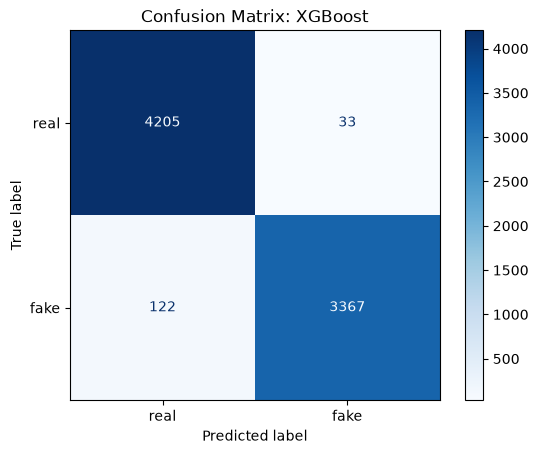

In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: XGBoost")
plt.show()

- True Positive, correctly caught fake article: 3,367
- False Negative, fake article predicted as real: 122
- False Positive, real article predicted as fake: 33
- True Negative, correctly identified real article: 4,205

99.0% of its "fake" flags are right (precision = 0.990). Compared with the baseline, it misses slightly more fakes (122 vs 108) but raises fewer false alarms (33 vs 44). The numbers are almost the same as LightGBM's (119 missed, 35 false alarms), and it misses about half as many fakes as the Random Forest (228).

## 8. Top-K Terms and Multicollinearity Check

With 5,000 terms, looking at every term isn't practical: ALE and ICE would need thousands of plots, and a 5,000 × 5,000 correlation matrix can't be read. So we focus on the 30 terms most linked to the label (K = 30), ranked by chi-squared on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. Higher means a stronger link to the label, but it doesn't show the direction. We use it because it doesn't depend on any model, so every notebook shares the same list. TF-IDF weights aren't counts, so the scores are only used for ranking, not as significance tests.

In [11]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,video,429.735134
1,said,354.357520
2,image,351.657391
3,via,273.043116
4,featured,245.148761
5,com,236.464647
6,hillary,229.692337


The top seven are video, said, image, via, featured, com and hillary, the same list as in the other notebooks since chi-squared doesn't depend on the model. Five of them (video, image, via, featured, com) are source fingerprints: embedded videos, photo credits and links on fake sites. said is Reuters' writing style, and hillary is the partisan naming fake sites use.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

The heatmap below shows how strongly the weights of each pair of top terms move together, from −1 (one goes up when the other goes down) to 1 (they go up together). If some terms move together, methods that treat each word on its own can give misleading results, so this decides which explanation methods we can use.

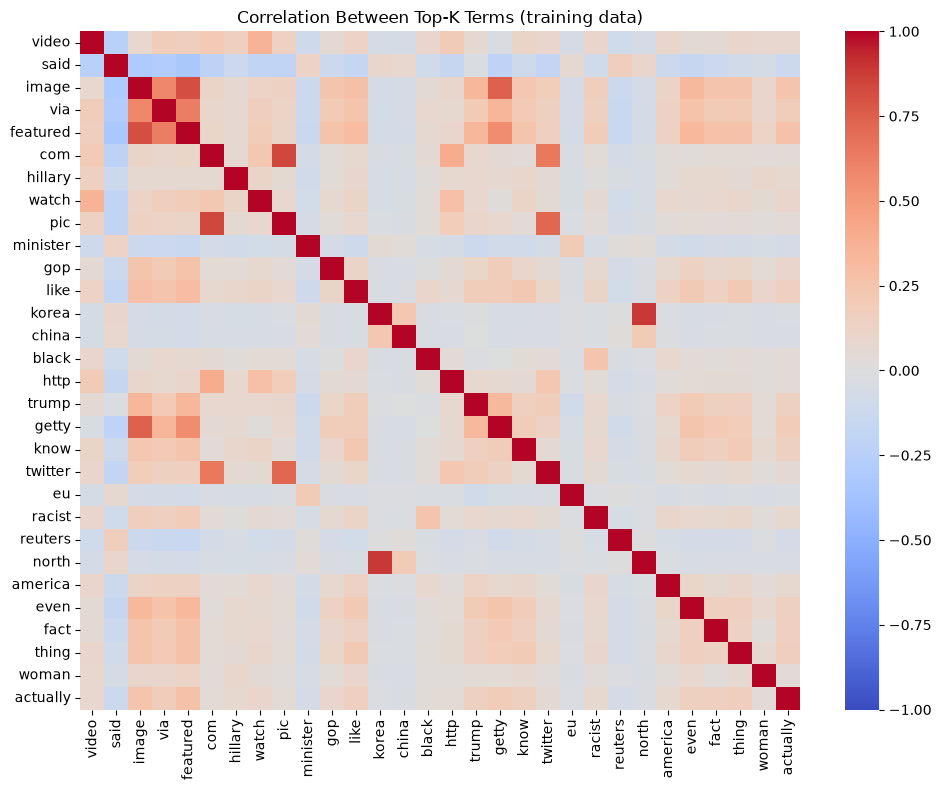

Pairs with |correlation| > 0.5:
korea     north       0.885267
com       pic         0.842176
image     featured    0.814060
          getty       0.743669
pic       twitter     0.721554
com       twitter     0.649922
via       featured    0.628802
image     via         0.579483
featured  getty       0.562061
dtype: float64


In [13]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Most cells are close to 0, but nine pairs go above 0.5, and they form three groups:

- **Photo credits:** image, featured, getty and via (0.56 to 0.81), all from "Featured image via Getty Images."
- **Links:** com, pic and twitter (0.65 to 0.84), from embedded tweets ("pic.twitter.com").
- **A name:** north and korea (0.89).

These words come as a package: an article that has one of them usually has the others. This rules out two explanation methods that assume the words are independent, plain PFI and PDP. We use grouped PFI (9.1) and ALE (10) instead, and ICE only uses terms outside these groups (11). Each section explains why. The check only covers the top 30 terms and linear relationships, so other dependencies may still exist.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Grouped Permutation Feature Importance (PFI)

PFI shuffles a term's values across the test articles and measures how much Fake-class recall drops (averaged over 5 repeats). A big drop means the model relies on that term to catch fakes.

**Why grouped and not plain PFI:** plain PFI shuffles one term at a time. If we shuffle only via, the article still has image, featured and getty, so the model can still spot the photo credit and barely notices. Each term then looks unimportant, even though the photo credit as a whole matters a lot. Grouped PFI shuffles correlated terms together, with the same row order, so the whole group is removed at once. Terms that aren't correlated with anything are still shuffled on their own, so for them it's the same as plain PFI.

That turns the 30 top terms into 24 units: three groups (image, via, featured, getty; com, pic, twitter; korea, north) and 21 single terms.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, groups, n_repeats=5, seed=RANDOM_STATE):
    """Shuffle each group of terms TOGETHER (same row order). A group is either a single term
    or a set of correlated terms, so correlated terms cannot stand in for each other."""
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for terms in groups:
        cols = [tfidf.vocabulary_[t] for t in terms]
        original = X_dense[:, cols].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, cols] = original[rng.permutation(len(original))]
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, cols] = original
        rows.append((", ".join(terms), np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# Merge the correlated pairs from Section 8 into groups (image-featured + image-getty -> one group)
term_groups = []
for a, b in high_pairs.index:
    linked = [g for g in term_groups if a in g or b in g]
    merged = {a, b}.union(*linked)
    term_groups = [g for g in term_groups if g not in linked] + [merged]

# Each correlated group is shuffled as one unit; every other top term on its own
pfi_groups = []
for t in top_terms:
    group = next((g for g in term_groups if t in g), {t})
    terms = [u for u in top_terms if u in group]          # keep chi-squared order
    if terms not in pfi_groups:
        pfi_groups.append(terms)

print(f"{len(top_terms)} top terms -> {len(pfi_groups)} PFI units")
base_recall, pfi_df = permutation_recall_drop(xgb_model, X_test_dense, y_test, pfi_groups)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

30 top terms -> 24 PFI units
Recall before shuffling: 0.9650


,term,mean_recall_drop,std
2,"image, via, featured, getty",0.058469,0.001570
1,said,0.024190,0.001949
0,video,0.013586,0.001237
17,reuters,0.010089,0.000839
6,minister,0.004299,0.001146
4,hillary,0.002121,0.000532
18,america,0.000860,0.000769


The photo-credit group matters most by far: shuffling it drops recall by 0.058, about 204 of the 3,489 fake test articles. said comes second at 0.024 (about 84 articles), then video (0.014, about 47) and reuters (0.010, about 35). minister and hillary are small (about 15 and 7 articles), and america barely registers.

This is almost exactly LightGBM's ranking (0.061 for the photo credit, 0.024 for said), and about three times the Random Forest's reliance on the photo credit (0.019).

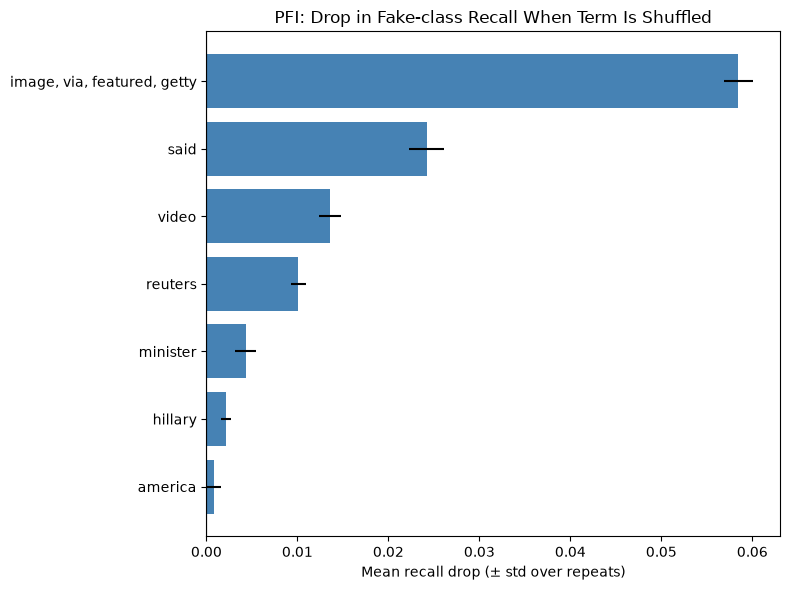

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The photo-credit group stands far ahead of everything else, with a narrow error bar. said, video and reuters follow, all clearly above zero. america's error bar reaches zero, so its effect can't be told apart from noise. The check below tests the rest against chance.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [16]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(xgb_model, X_test_dense, y_test, [[feature_names[i]] for i in other_idx])
print(pfi_null["mean_recall_drop"].describe())

count    30.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: mean_recall_drop, dtype: float64


Every one of the 30 random terms has a drop of exactly zero. XGBoost's small trees only split on a limited set of terms, and none of these random ones is among them, so shuffling them can't change any prediction. Every top unit except america is clearly above that, so their effects are real.

### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term, starting from the model's average output. TreeSHAP calculates these values exactly for tree models. They are computed for the same 200 test articles as in the other notebooks and then averaged.

For XGBoost, SHAP values are in log-odds, not probability. Positive values push toward fake and negative values toward real. Near a probability of 0.5, a change of 0.1 in log-odds is about 2.5 percentage points.

Further from 0.5, the same change moves the probability much less: at 0.99, 0.1 in log-odds is only about 0.1 points. That's why articles the model is already sure about barely move in the ICE plots below, even when a word has a large log-odds effect.

In [17]:
explainer_shap = shap.TreeExplainer(xgb_model)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 5000)


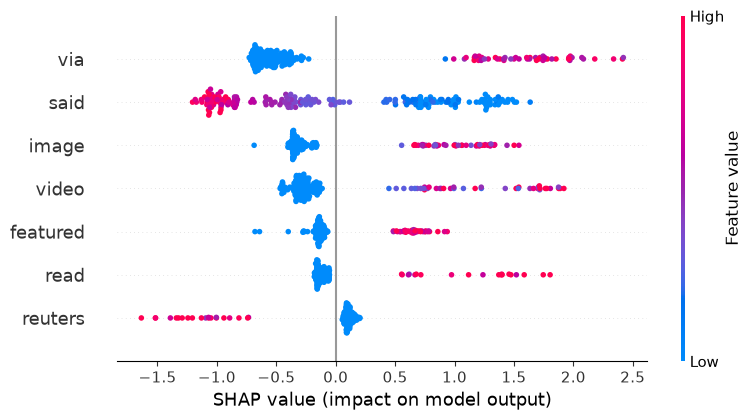

In [18]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [19]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
4789,via,0.830983
3905,said,0.786409
2206,image,0.486318
4793,video,0.472243
1705,featured,0.251614
3605,read,0.224677
3801,reuters,0.219534


Each dot is one article: its position shows how much a term pushed the output toward fake (right) or real (left), in log-odds, and its color shows the term's weight (red high, blue low or absent).

via is the strongest term. Articles that contain it are pushed toward fake by about 1 to 2.5 log-odds, and articles without it are pushed toward real by about 0.6, so its absence matters too. said works the other way: frequent use pushes toward real (about −1), and articles without it are pushed toward fake by up to about 1.6. image, video, featured and read ("READ MORE" links) push toward fake when present, and reuters pushes strongly toward real (about −0.8 to −1.7) in the articles that mention it.

The top seven are the same terms as LightGBM's, with almost the same sizes. SHAP and grouped PFI agree on the main picture: the photo credit (led by via) and said are the two biggest signals, with video and reuters next.

## 10. Feature Effects (ALE)

ALE shows how the predicted probability of fake changes as one term's weight goes up, so it shows the direction and size of each term's effect.

**Why ALE and not PDP:** PDP sets a term to each value in every article while leaving the rest of the article alone. For correlated terms that creates articles that can't exist, such as a photo credit with "image" but no "featured" or "getty", and the curve then describes those fake articles instead of real ones. ALE avoids this. It cuts the term's weights into small intervals and, in each interval, only uses the articles whose weight is actually in that interval. It measures how the prediction changes across that small step, then adds the steps up. 0 on the y-axis means the average prediction.

We plot the six top chi-squared terms: video, said, image, via, featured and com. Most articles don't contain a given term, so the first interval runs from 0 (absent) to the smallest weight at which the term shows up.

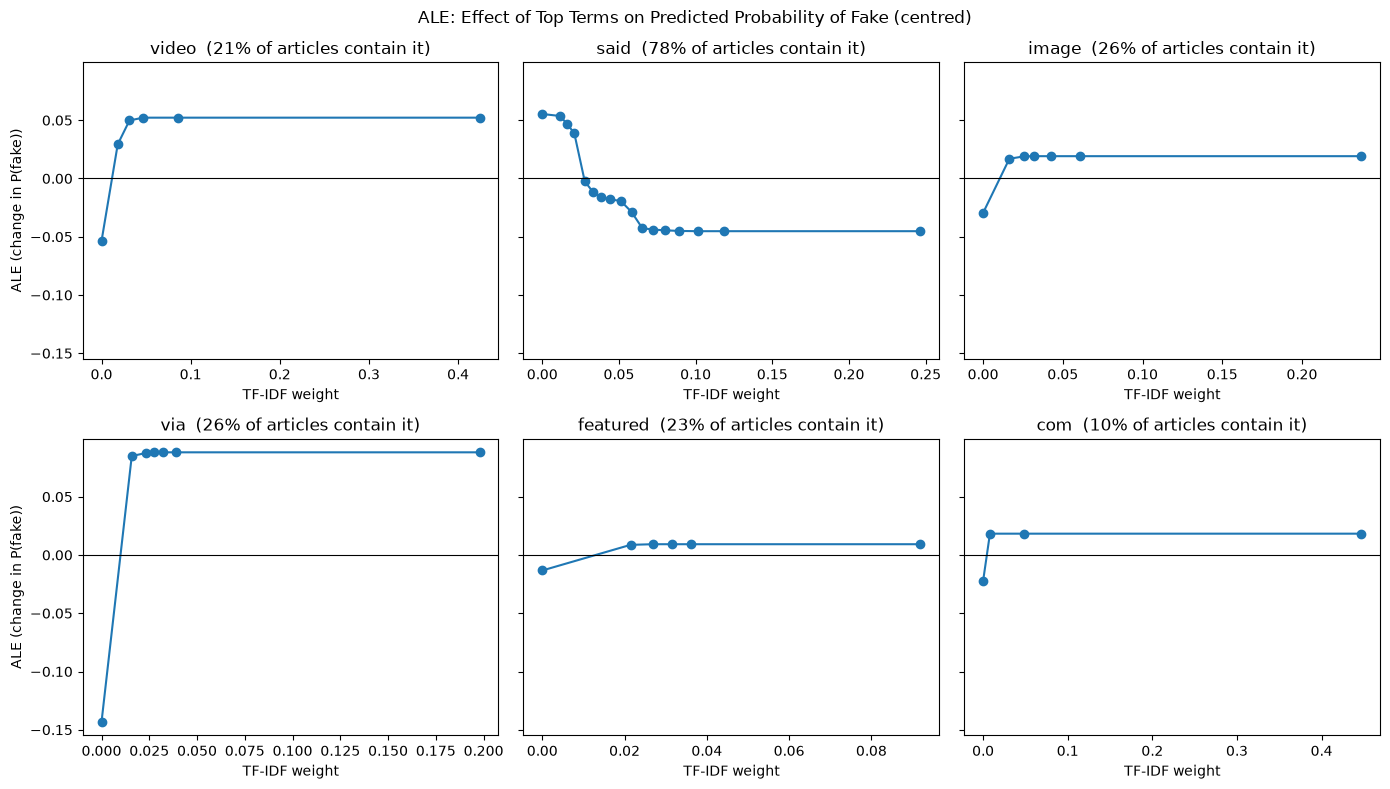

In [20]:
def ale_1d(predict, X, col, n_bins=20):
    """First-order ALE for one column. Bins are quantiles of the column, so most of the
    mass at weight 0 collapses into one edge. Returns bin edges and centred ALE values."""
    x = X[:, col]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:
        return edges, np.zeros(len(edges))
    # article in interval (edges[k-1], edges[k]] -> bin k; articles exactly at the lowest edge go to bin 1
    bin_idx = np.clip(np.searchsorted(edges, x, side="left"), 1, len(edges) - 1)
    effects = np.zeros(len(edges) - 1)
    counts = np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        rows = X[bin_idx == k]
        if len(rows) == 0:
            continue
        lo, hi = rows.copy(), rows.copy()
        lo[:, col], hi[:, col] = edges[k - 1], edges[k]
        effects[k - 1] = (predict(hi) - predict(lo)).mean()   # local effect, using only articles in this bin
        counts[k - 1] = len(rows)
    ale = np.concatenate([[0.0], np.cumsum(effects)])         # accumulate the local effects
    mids = (ale[:-1] + ale[1:]) / 2
    ale -= (mids * counts).sum() / counts.sum()               # centre so the average effect is 0
    return edges, ale

ale_terms = list(top_terms[:6])
predict_fake = lambda X: xgb_model.predict_proba(X)[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, term in zip(axes.ravel(), ale_terms):
    col = tfidf.vocabulary_[term]
    edges, ale = ale_1d(predict_fake, X_test_dense, col)
    ax.plot(edges, ale, marker="o")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{term}  ({(X_test_dense[:, col] > 0).mean():.0%} of articles contain it)")
    ax.set_xlabel("TF-IDF weight")
for ax in axes[:, 0]:
    ax.set_ylabel("ALE (change in P(fake))")
fig.suptitle("ALE: Effect of Top Terms on Predicted Probability of Fake (centred)")
plt.tight_layout()
plt.show()

via dwarfs the rest: from absent to present, it moves the predicted probability by about 23 points. video and said each move it by about 10 points, said in the real direction and spread over a range of weights (roughly 0.015 to 0.065), so it's frequent use that counts. image, com and featured move it by only about 2 to 5 points.

As with LightGBM, this is the correlation showing up. image, featured and via almost always appear together, and the model uses via as its main signal for the whole photo credit, so image and featured add little once via is known. ALE measures each term among the articles that actually have it, so it shows this instead of crediting each word with the full effect of the credit line.

The directions match SHAP and the baseline: the fingerprint terms, including video, push toward fake, and said toward real.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, to show whether a term affects every article the same way.

ICE works like PDP, one article at a time, so it has the same problem with correlated terms, and there is no ALE version of it. So ICE only uses the top terms that aren't in any correlated group: video, said, hillary, watch, minister and gop.

ICE terms: ['video', 'said', 'hillary', 'watch', 'minister', 'gop']


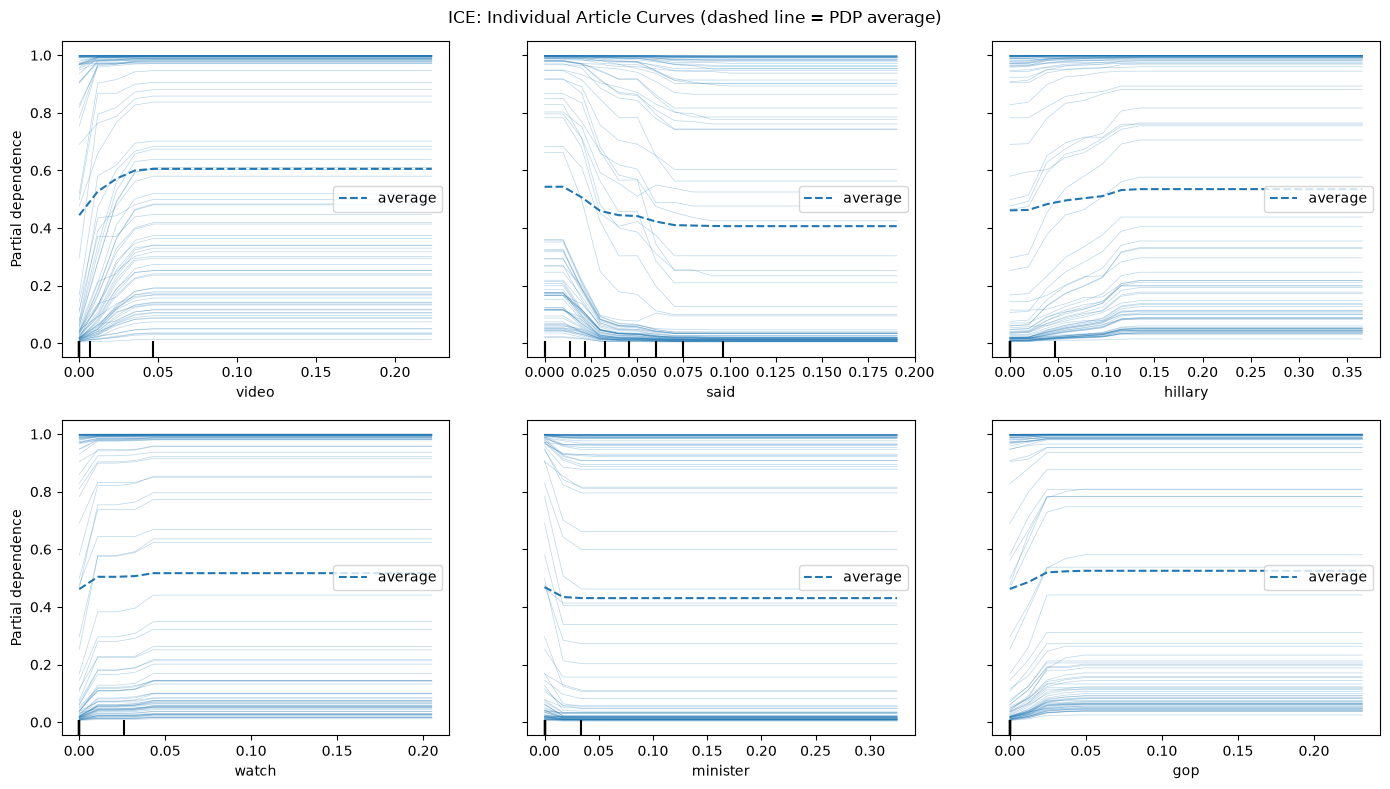

In [21]:
# ICE has no ALE version, so it only uses terms that are not part of any correlated pair
correlated_terms = {t for g in term_groups for t in g}
ice_idx = [i for i in top_idx if feature_names[i] not in correlated_terms][:6]
print("ICE terms:", list(feature_names[ice_idx]))

ice_display = PartialDependenceDisplay.from_estimator(
    xgb_model, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the average. Many lines sit close to 0 or 1 and barely move: XGBoost is already very sure about those articles from their other words, so one word can't change much.

The lines in the middle move a lot more. Adding video can take an article from near 0 to about 0.6, and adding said can take one from about 0.6 down to almost 0. The centered plot below shows the size of these changes more clearly.

### 11.1 Centered ICE

The ICE plot can be misleading. Each line starts at a different height, set by the article's other words, so a line that starts high and moves a little looks the same as one that starts low and moves a lot. That makes it hard to compare how much the term actually changes each article.

Centered ICE fixes this by shifting every line to start at 0. Each line then shows only the change in predicted probability when the term is added to that article, so the size of the effect can be compared directly across articles.

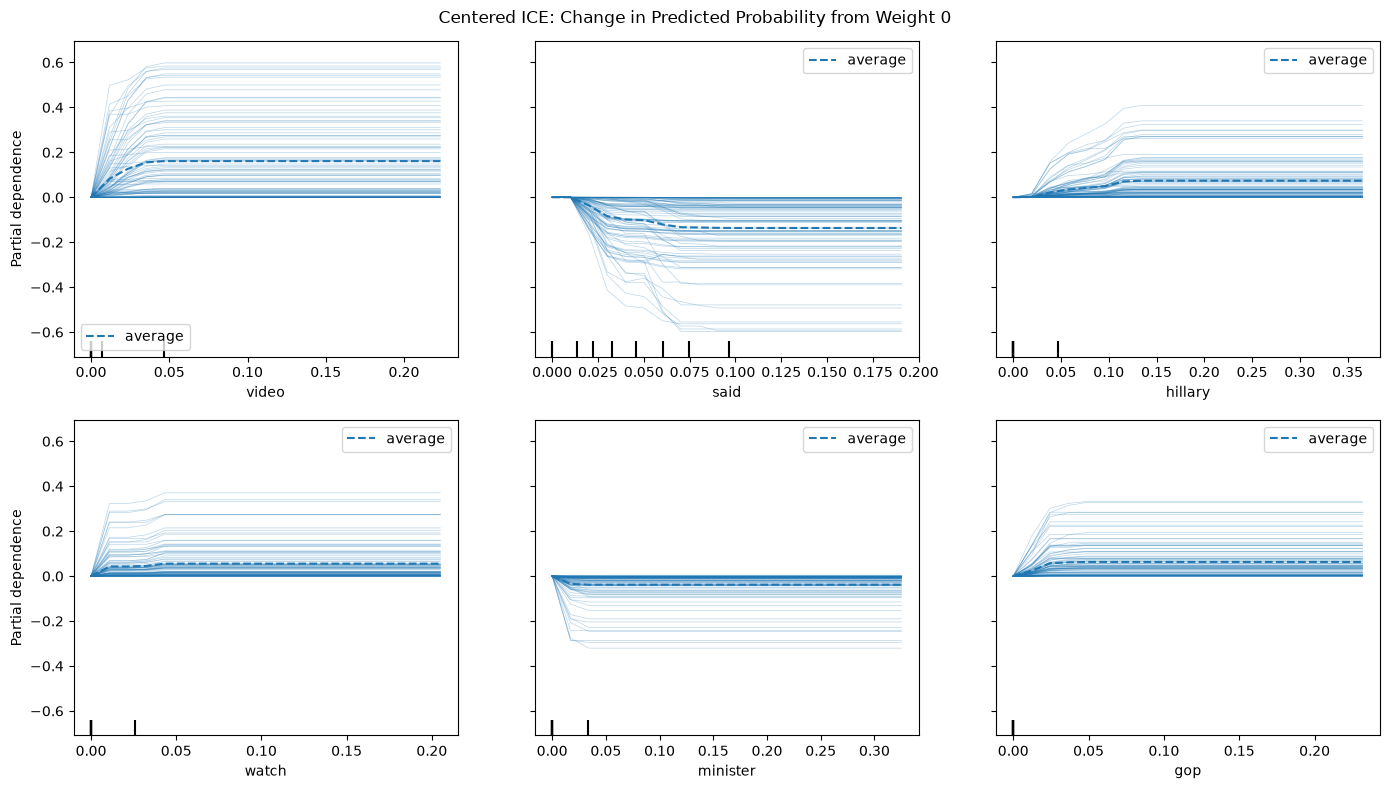

In [22]:
cice_display = PartialDependenceDisplay.from_estimator(
    xgb_model, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

Every panel goes one way only. Adding video raises articles by about 16 points on average and by up to about 60 for some. said lowers them by about 14 on average and up to about 60. hillary, watch and gop push up (by up to about 41, 37 and 33 points), and minister pushes down (by up to about 31).

As with LightGBM, many lines stay near 0 because the model was already sure about those articles, while a few uncertain ones swing by more than half the scale. So the direction of each term is consistent, but how much it matters depends on how sure the model already was.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [23]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    # XGBoost was trained on dense arrays, so the TF-IDF output is converted to dense here as well
    return xgb_model.predict_proba(tfidf.transform(texts).toarray().astype(np.float32))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = xgb_model.predict_proba(X_test_dense)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It doesn't look at the label or subject, so we check those afterwards.

In [24]:
N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [25]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "subject": [df.loc[y_test.index[i], "subject"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,subject,true_label,P(fake),outcome
0,News,fake,0.997,"TP (fake, caught)"
1,politicsNews,real,0.007,"TN (real, correct)"
2,politicsNews,real,0.022,"TN (real, correct)"
3,US_News,fake,0.888,"TP (fake, caught)"
4,News,fake,0.999,"TP (fake, caught)"


SP-LIME pick 1 | P(fake) = 0.997


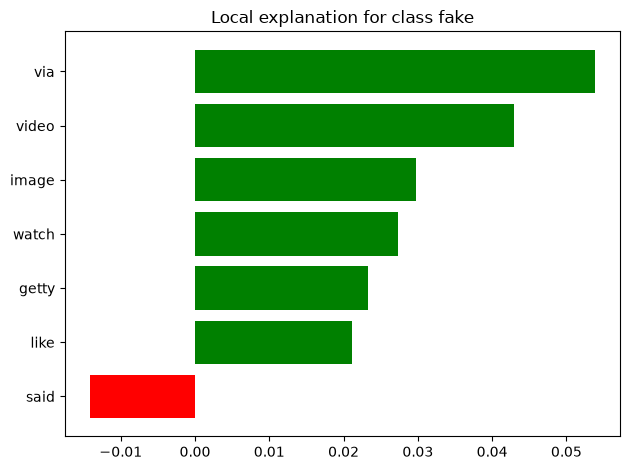

SP-LIME pick 2 | P(fake) = 0.007


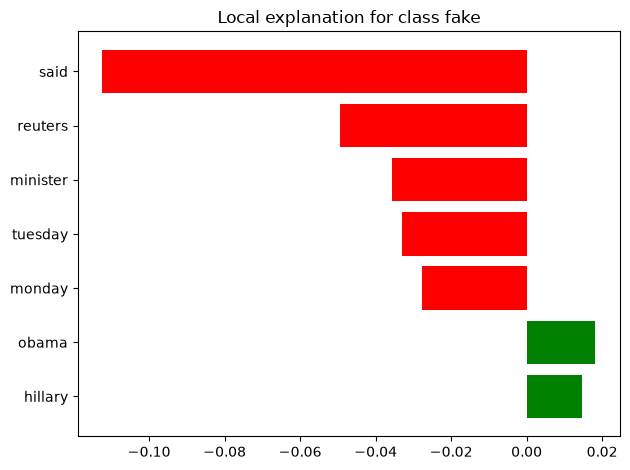

SP-LIME pick 3 | P(fake) = 0.022


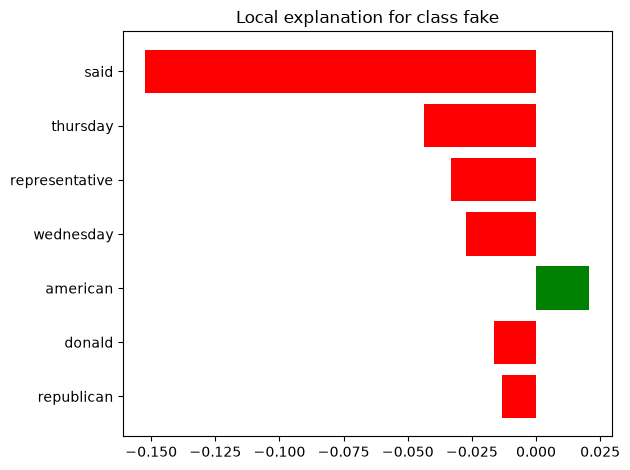

SP-LIME pick 4 | P(fake) = 0.888


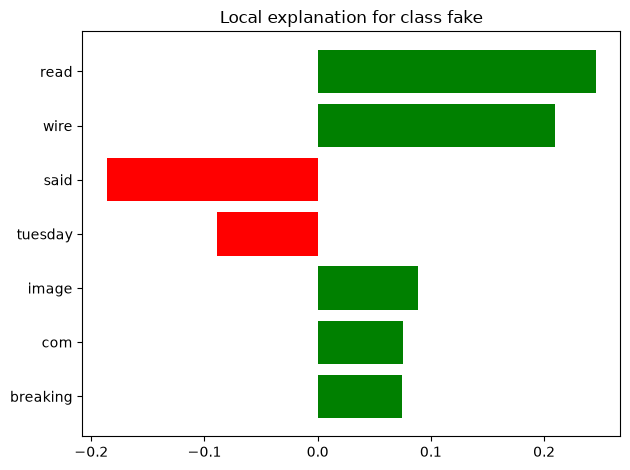

SP-LIME pick 5 | P(fake) = 0.999


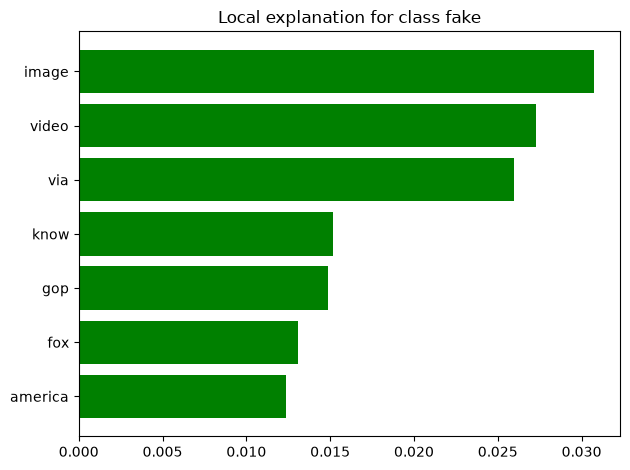

In [26]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The picks are three fake articles and two real ones, and XGBoost gets all five right. The subject column just mirrors the label (see `dataset_eda.ipynb`). All five are confident calls: 0.997, 0.888 and 0.999 for the fakes, 0.007 and 0.022 for the real ones.

**Pick 1 (fake, 0.997).** via, video, image, watch and getty push toward fake: the photo credit plus a video. Only said pulls slightly toward real.

**Pick 2 (real, 0.007).** said (−0.11), reuters, minister, tuesday and monday pull toward real. obama and hillary push slightly toward fake.

**Pick 3 (real, 0.022).** said (−0.15) again does most of the work, with thursday, representative and wednesday.

**Pick 4 (fake, 0.888).** read ("READ MORE") and wire (a site sign-off like "21st Century Wire") push hard toward fake (about 0.25 and 0.21), with image, com and breaking. said and tuesday pull back but lose.

**Pick 5 (fake, 0.999).** image, video and via again, with know, gop, fox and america. The weights are small because the model is already sure.

The fakes are caught on fingerprints (photo credits, "READ MORE", site sign-offs) and the real ones on Reuters' style, above all said, just as with LightGBM.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 1.000


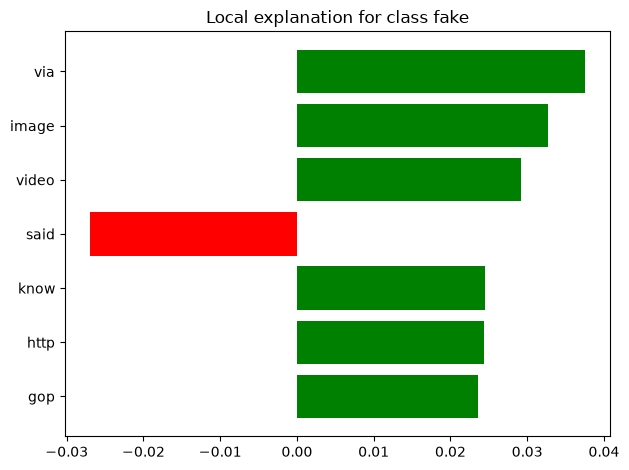

False Negative (fake, missed) | P(fake) = 0.017


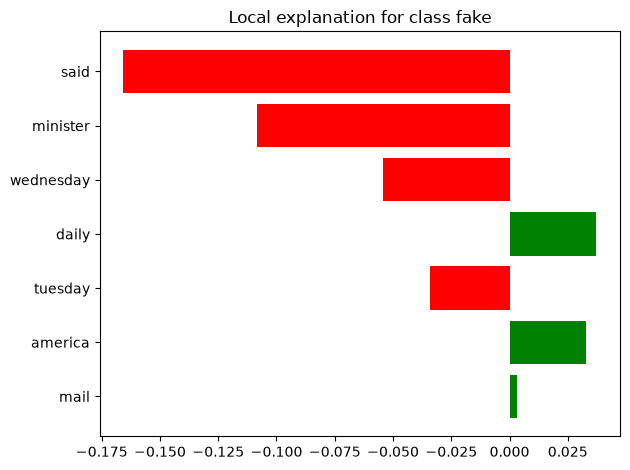

False Positive (real, flagged) | P(fake) = 0.920


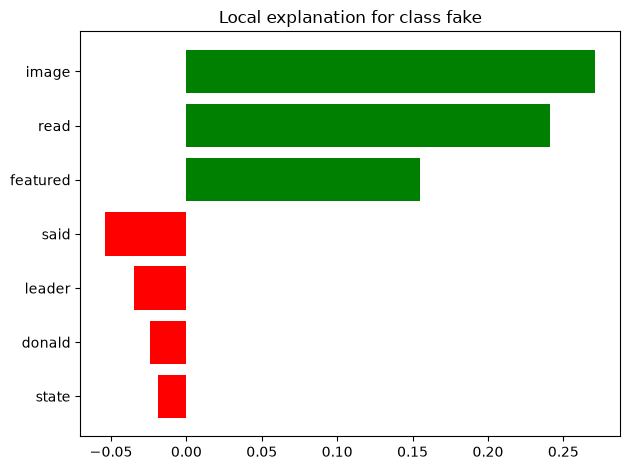

In [27]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

To see which articles these are, the cell below prints their headlines. The descriptions that follow refer to them.

In [29]:
for name, i in cases.items():
    print(name, "|", df.loc[y_test.index[i], "title"][:90])

True Positive (fake, caught) | Watch Lindsey Graham Accept Defeat Over Trump: ‘I Can’t Go Where He’s Taking The Country’ 
False Negative (fake, missed) | ISRAEL WILL NAME New Train Station Near Western Wall After President Donald Trump
False Positive (real, flagged) | 'Mad dog' anti-Trump leaflets, suspected floated in from North Korea, turn up in Seoul


These are the most extreme articles in each group.

**True Positive (P(fake) = 1.000).** The fake article ("Watch Lindsey Graham Accept Defeat Over Trump: 'I Can't Go Where He's Taking The Country'") is caught on via, image, video, know, http and gop, and only said pulls slightly back. All the weights are small (under 0.04), because the model is completely sure: removing a few words can't move a prediction of 1.000. The words are the photo credit, an embedded video and link, and partisan naming, not anything the article claims.

**False Negative (P(fake) = 0.017).** The fake article ("ISRAEL WILL NAME New Train Station Near Western Wall After President Donald Trump") reads like a wire report. said (−0.17), minister (−0.11), wednesday and tuesday pull toward real, and only daily and america push toward fake. With no photo credit and wire-style wording, the model is almost sure it's real.

**False Positive (P(fake) = 0.920).** The real Reuters article ("'Mad dog' anti-Trump leaflets, suspected floated in from North Korea, turn up in Seoul") is about leaflets, so it naturally talks about their images and what they read. image, read and featured push toward fake (0.16 to 0.27 each), more than said, leader and donald can pull back. On fake sites these words come from photo credits and "READ MORE" links; here they're used in their normal sense.

These are the same two articles LightGBM got most wrong, with the same words behind each mistake. Both models react to specific words, not to what the words mean.

LIME uses random samples, so results change a little between runs, especially for the smaller words.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while SHAP splits the model's own output into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case. Values are in log-odds.

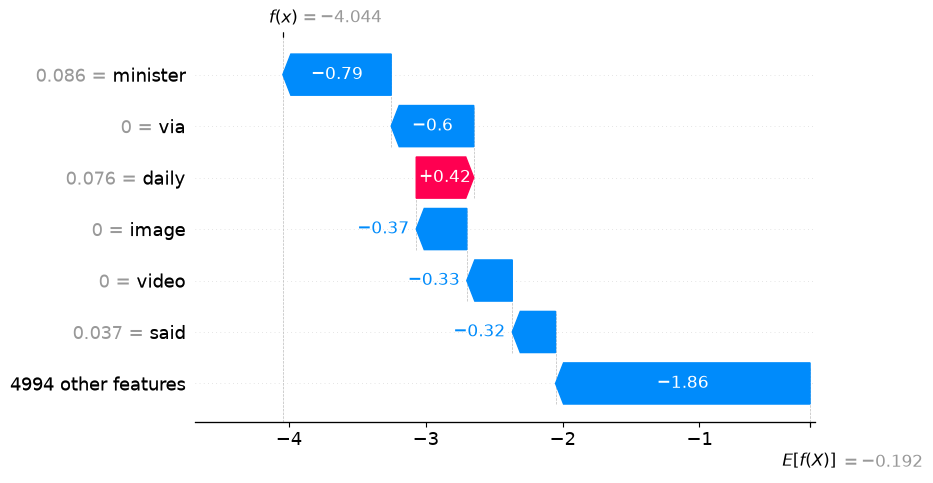

In [28]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at −0.192 log-odds (a probability of about 0.45), the model's average output, and ends at −4.04 (a probability of 0.017) for this missed fake.

minister pushes hardest toward real (−0.79). Then come words the article doesn't have: via (−0.60), image (−0.37) and video (−0.33). So the missing photo credit and video together add about −1.3. said adds −0.32. daily is the only term pushing toward fake (+0.42). The other 4,994 terms add −1.86, about half the total.

SHAP and LIME agree on the main words: minister and said toward real, daily toward fake. SHAP adds what LIME can't show: much of the push toward real comes from the photo credit and video that aren't there.

## 13. Summary

XGBoost catches 96.5% of fake articles (recall 0.9650) with precision 0.990, accuracy 0.980 and ROC AUC 0.998. That matches the Logistic Regression baseline on accuracy and comes close on recall (0.969). It misses slightly more fakes than the baseline (122 vs 108) but raises fewer false alarms (33 vs 44). Training and test recall are almost the same, so it isn't overfitting.

Several top terms come as packages, so we used grouped PFI instead of plain PFI and ALE instead of PDP. The methods agree on what XGBoost relies on:

- **Grouped PFI:** the photo-credit group matters most (recall drop 0.058, about 204 fake articles), well ahead of said (0.024), video and reuters.
- **TreeSHAP:** via and said are the strongest terms, and the absence of via pushes toward real.
- **ALE:** via alone moves the prediction by about 23 points. Once via is known, image and featured add little, since they come with it.
- **ICE:** each term pushes every article the same way, but articles the model is already sure about barely move, while uncertain ones can swing by more than half the scale.
- **LIME:** fakes are caught on fingerprints and real articles on said. The worst errors are a fake article written like a wire report and a real article about leaflets, flagged because it uses "image" and "read" in their normal sense.
- **SHAP waterfall:** for the missed fake, the missing photo credit and video are among the biggest reasons it was called real.

XGBoost and LightGBM are two different boosting libraries, yet they end up with almost the same accuracy, the same top terms, the same ALE curves and even the same worst mistakes. That makes these explanations more trustworthy: they describe the data and the boosting approach, not a quirk of one library.

Like LightGBM, XGBoost matches the baseline by leaning heavily on the photo credit, a page-layout fingerprint of the fake sites. It judges how an article is written and laid out, not whether what it says is true.